In [12]:
import numpy as np
import cv2
import matplotlib.pyplot as plt


image = cv2.imread('periodic_noise.jpg', cv2.IMREAD_GRAYSCALE)

**Задание 1**

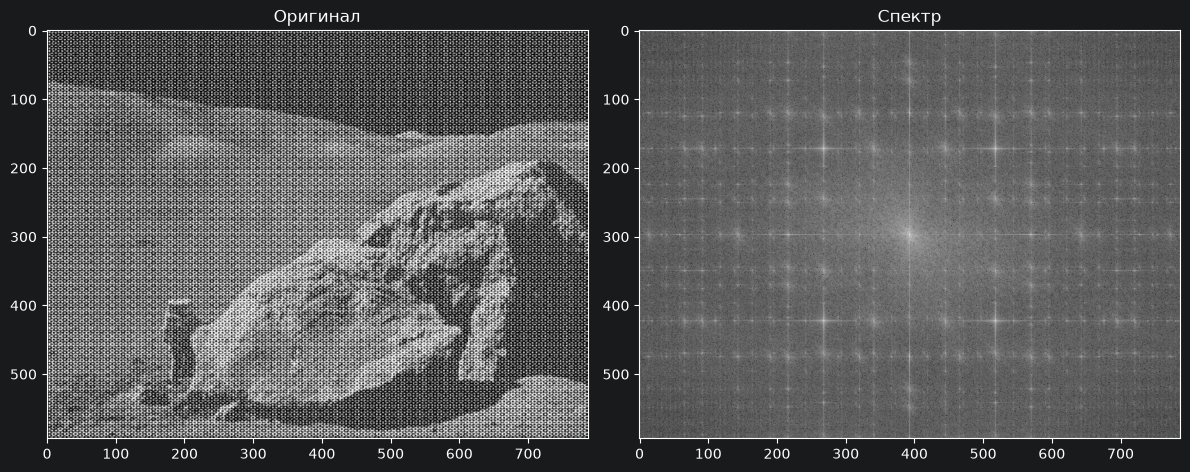

In [13]:
dft = cv2.dft(np.float32(image), flags=cv2.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft, axes=(0, 1))

magnitude = cv2.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1])
spectrum = 20 * np.log(magnitude + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title('Оригинал')

plt.subplot(1, 2, 2)
plt.imshow(spectrum, cmap='gray')
plt.title('Спектр')

plt.tight_layout()
plt.show()

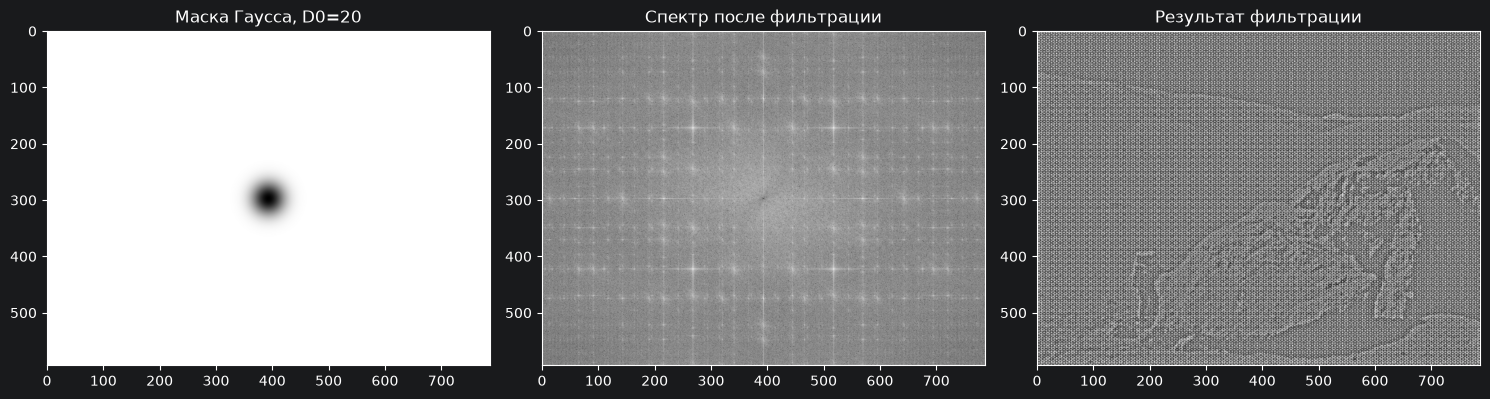

In [14]:
D0 = 20
h, w = image.shape
cy, cx = h // 2, w // 2

y = np.arange(h) - cy
x = np.arange(w) - cx
yy, xx = np.meshgrid(y, x, indexing='ij')

D2 = yy**2 + xx**2
hp = 1 - np.exp(-D2 / (2 * D0**2))

mask = np.zeros((h, w, 2), np.float32)
mask[:, :, 0] = hp
mask[:, :, 1] = hp

filtered = dft_shift * mask

magnitude = cv2.magnitude(filtered[:, :, 0], filtered[:, :, 1])
filtered_spectrum = 20 * np.log(magnitude + 1)

image_hp = cv2.idft(
    np.fft.ifftshift(filtered, axes=(0, 1)),
    flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(mask[:, :, 0], cmap='gray')
plt.title(f'Маска Гаусса, D0={D0}')

plt.subplot(1, 3, 2)
plt.imshow(filtered_spectrum, cmap='gray')
plt.title('Спектр после фильтрации')

plt.subplot(1, 3, 3)
plt.imshow(image_hp, cmap='gray')
plt.title('Результат фильтрации')

plt.tight_layout()
plt.show()

**Задание 2**

Максимальная разница внутри: 0.00018310547


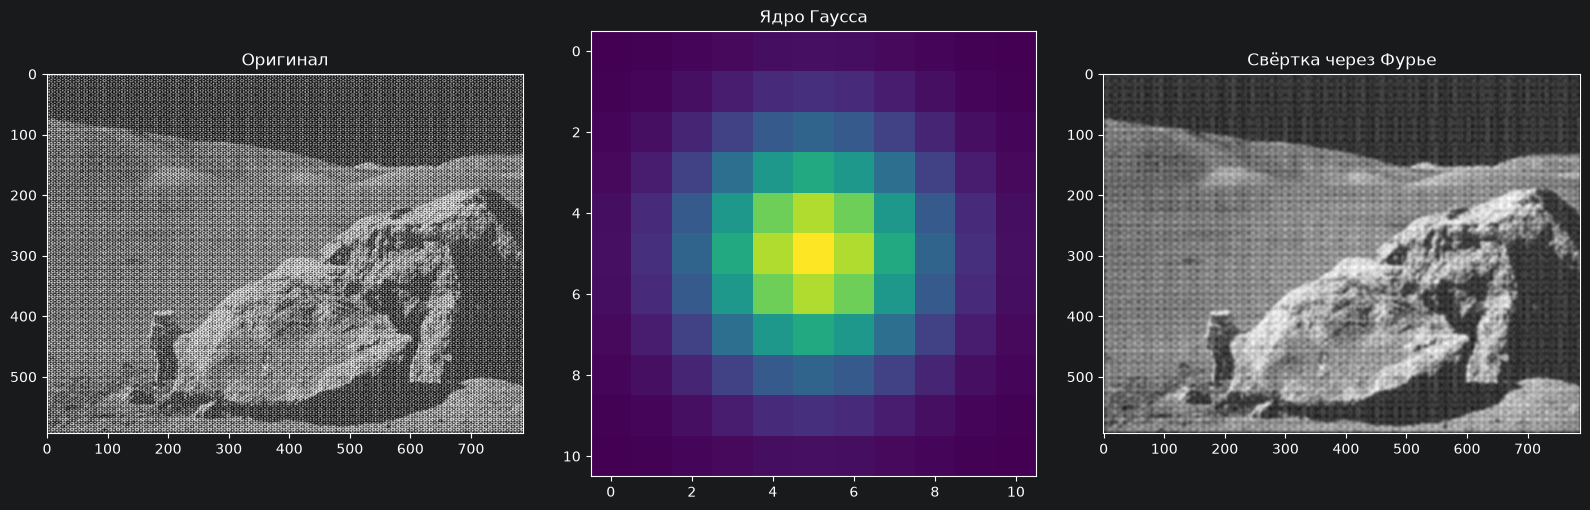

In [15]:
ksize = 11
sigma = 2.0

ax = np.arange(-(ksize // 2), ksize // 2 + 1)
xx, yy = np.meshgrid(ax, ax)

kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
kernel = (kernel / kernel.sum()).astype(np.float32)

kh, kw = kernel.shape
kernel_pad = np.zeros((h, w), np.float32)
kernel_pad[:kh, :kw] = kernel

kernel_pad = np.roll(
    kernel_pad,
    (-(kh // 2), -(kw // 2)),
    axis=(0, 1)
)

dft_image = cv2.dft(
    np.float32(image),
    flags=cv2.DFT_COMPLEX_OUTPUT
)
dft_kernel = cv2.dft(kernel_pad, flags=cv2.DFT_COMPLEX_OUTPUT)

prod = cv2.mulSpectrums(dft_image, dft_kernel, flags=0)

conv = cv2.idft(
    prod,
    flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT
)

conv_ref = cv2.filter2D(np.float32(image), -1, kernel)

diff = np.abs(conv - conv_ref)
diff_inner = diff[ksize:-ksize, ksize:-ksize]

print('Максимальная разница внутри:', diff_inner.max())

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Оригинал')

plt.subplot(1, 3, 2)
plt.imshow(kernel, cmap='viridis')
plt.title('Ядро Гаусса')

plt.subplot(1, 3, 3)
plt.imshow(conv, cmap='gray')
plt.title('Свёртка через Фурье')

plt.tight_layout()
plt.show()

**Задание 3**

найденные пики: 465


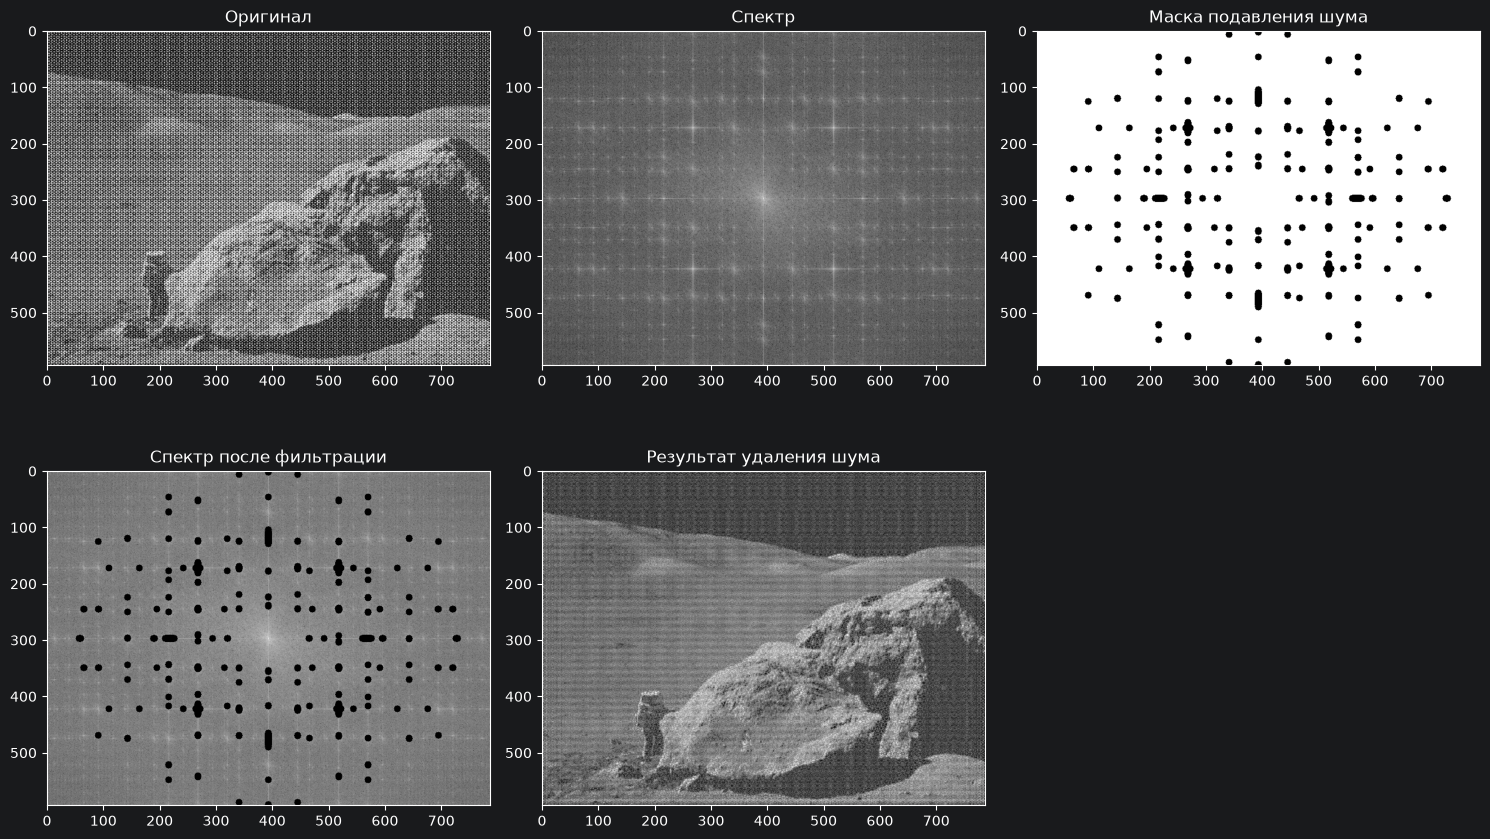

In [16]:
dft = cv2.dft(np.float32(image), flags=cv2.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft, axes=(0, 1))

magnitude = cv2.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1])
spectrum = 20 * np.log(magnitude + 1)

T = 250
R = 50
r = 6

points = np.argwhere(spectrum > T)
notch_mask = np.ones((h, w), np.float32)
count = 0

for y, x in points:
    if (y - cy)**2 + (x - cx)**2 > R**2:
        cv2.circle(notch_mask, (int(x), int(y)), r, 0, -1)

        sym_y = (2 * cy - int(y)) % h
        sym_x = (2 * cx - int(x)) % w
        cv2.circle(notch_mask, (sym_x, sym_y), r, 0, -1)

        count += 1

print('найденные пики:', count)

mask = np.dstack([notch_mask, notch_mask])
filtered = dft_shift * mask

magnitude = cv2.magnitude(filtered[:, :, 0], filtered[:, :, 1])
filtered_spectrum = 20 * np.log(magnitude + 1)

image_clean = cv2.idft(
    np.fft.ifftshift(filtered, axes=(0, 1)),
    flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT
)
image_clean = np.clip(image_clean, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 9))

plt.subplot(2, 3, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Оригинал')

plt.subplot(2, 3, 2)
plt.imshow(spectrum, cmap='gray')
plt.title('Спектр')

plt.subplot(2, 3, 3)
plt.imshow(notch_mask, cmap='gray')
plt.title('Маска подавления шума')

plt.subplot(2, 3, 4)
plt.imshow(filtered_spectrum, cmap='gray')
plt.title('Спектр после фильтрации')

plt.subplot(2, 3, 5)
plt.imshow(image_clean, cmap='gray', vmin=0, vmax=255)
plt.title('Результат удаления шума')

plt.tight_layout()
plt.show()